In [1]:
# Import erforderlicher Bibliotheken
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Plotting-Stil
plt.style.use('default')
plt.rcParams['figure.figsize'] = [15, 10]
sns.set_style("whitegrid")

# Verzeichnisse
results_dir = os.path.join(os.path.dirname(os.getcwd()), "results")
print(f"📁 Ergebnisverzeichnis: {results_dir}")

📁 Ergebnisverzeichnis: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_h2_spitzenzeiten_case_study/results


In [2]:
# Szenarien und Flottengrößen definieren
scenarios = {
    'klagenfurt_h2_spitzenzeiten_scenario_1': 8,
    'klagenfurt_h2_spitzenzeiten_scenario_2': 16,
    'klagenfurt_h2_spitzenzeiten_scenario_3': 24,
    'klagenfurt_h2_spitzenzeiten_scenario_4': 32
}

summary_data = []

print("="*80)
print("H2: MINIMALE FLOTTENGRÖSSE ANALYSE")
print("="*80)
print("\n⚙️  Fahrzeugkonfiguration: 8 Sitzplätze pro Fahrzeug\n")

for scenario, fleet_size in scenarios.items():
    users_file = os.path.join(results_dir, scenario, '1_user-stats.csv')
    df = pd.read_csv(users_file)

    # Service-Berechnung basierend auf pickup_time
    served = df[df['pickup_time'].notna()]
    service_rate = len(served) / len(df) * 100

    print(f'\n{"="*60}')
    print(f'{scenario.split("_")[-1].upper()}: {fleet_size} Fahrzeuge (Gesamtkapazität: {fleet_size * 8} Sitzplätze)')
    print(f'{"="*60}')
    print(f'  Gesamtanfragen: {len(df)}')
    print(f'  ✅ Bediente Anfragen: {len(served)}')
    print(f'  📈 Service-Rate: {service_rate:.1f}%')

    if len(served) > 0:
        wait_times = (served['pickup_time'] - served['rq_time']) / 60
        drive_times = (served['dropoff_time'] - served['pickup_time']) / 60

        print(f'\n  ⏱️  Wartezeitmetriken:')
        print(f'     Durchschn.: {wait_times.mean():.1f} min')
        print(f'     Median: {wait_times.median():.1f} min')

        print(f'\n  🚗 Flottenauslastung:')
        print(f'     Genutzte Fahrzeuge: {served["vehicle_id"].nunique()}/{fleet_size}')
        print(f'     Auslastung: {served["vehicle_id"].nunique() / fleet_size * 100:.1f}%')

        summary_data.append({
            'Fleet Size': fleet_size,
            'Total Requests': len(df),
            'Served': len(served),
            'Service Rate (%)': round(service_rate, 1),
            'Avg Wait Time (min)': round(wait_times.mean(), 1),
            'Avg In-Vehicle Time (min)': round(drive_times.mean(), 1),
            'Avg Total Time (min)': round((wait_times + drive_times).mean(), 1),
            'Avg Occupancy': round(served["vehicle_id"].nunique() / fleet_size, 2)
        })

# DataFrame erstellen und speichern
summary_df = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("ZUSAMMENFASSUNG")
print("="*80)
display(summary_df)

# CSV speichern
summary_file = os.path.join(results_dir, 'klagenfurt_h2_spitzenzeiten_scenarios_comparison.csv')
summary_df.to_csv(summary_file, index=False)
print(f"\n💾 Gespeichert: {summary_file}")

H2: MINIMALE FLOTTENGRÖSSE ANALYSE

⚙️  Fahrzeugkonfiguration: 8 Sitzplätze pro Fahrzeug


1: 8 Fahrzeuge (Gesamtkapazität: 64 Sitzplätze)
  Gesamtanfragen: 100
  ✅ Bediente Anfragen: 41
  📈 Service-Rate: 41.0%

  ⏱️  Wartezeitmetriken:
     Durchschn.: 5.3 min
     Median: 5.5 min

  🚗 Flottenauslastung:
     Genutzte Fahrzeuge: 8/8
     Auslastung: 100.0%

2: 16 Fahrzeuge (Gesamtkapazität: 128 Sitzplätze)
  Gesamtanfragen: 100
  ✅ Bediente Anfragen: 70
  📈 Service-Rate: 70.0%

  ⏱️  Wartezeitmetriken:
     Durchschn.: 5.0 min
     Median: 5.4 min

  🚗 Flottenauslastung:
     Genutzte Fahrzeuge: 16/16
     Auslastung: 100.0%

3: 24 Fahrzeuge (Gesamtkapazität: 192 Sitzplätze)
  Gesamtanfragen: 100
  ✅ Bediente Anfragen: 92
  📈 Service-Rate: 92.0%

  ⏱️  Wartezeitmetriken:
     Durchschn.: 4.7 min
     Median: 4.5 min

  🚗 Flottenauslastung:
     Genutzte Fahrzeuge: 24/24
     Auslastung: 100.0%

4: 32 Fahrzeuge (Gesamtkapazität: 256 Sitzplätze)
  Gesamtanfragen: 100
  ✅ Bediente Anfrag

,Fleet Size,Total Requests,Served,Service Rate (%),Avg Wait Time (min),Avg In-Vehicle Time (min),Avg Total Time (min),Avg Occupancy
0,8,100,41,41.0,5.3,14.5,19.8,1.00
1,16,100,70,70.0,5.0,13.4,18.5,1.00
2,24,100,92,92.0,4.7,13.6,18.2,1.00
3,32,100,95,95.0,4.1,13.0,17.1,0.97



💾 Gespeichert: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_h2_spitzenzeiten_case_study/results/klagenfurt_h2_spitzenzeiten_scenarios_comparison.csv


📊 Visualisierung gespeichert


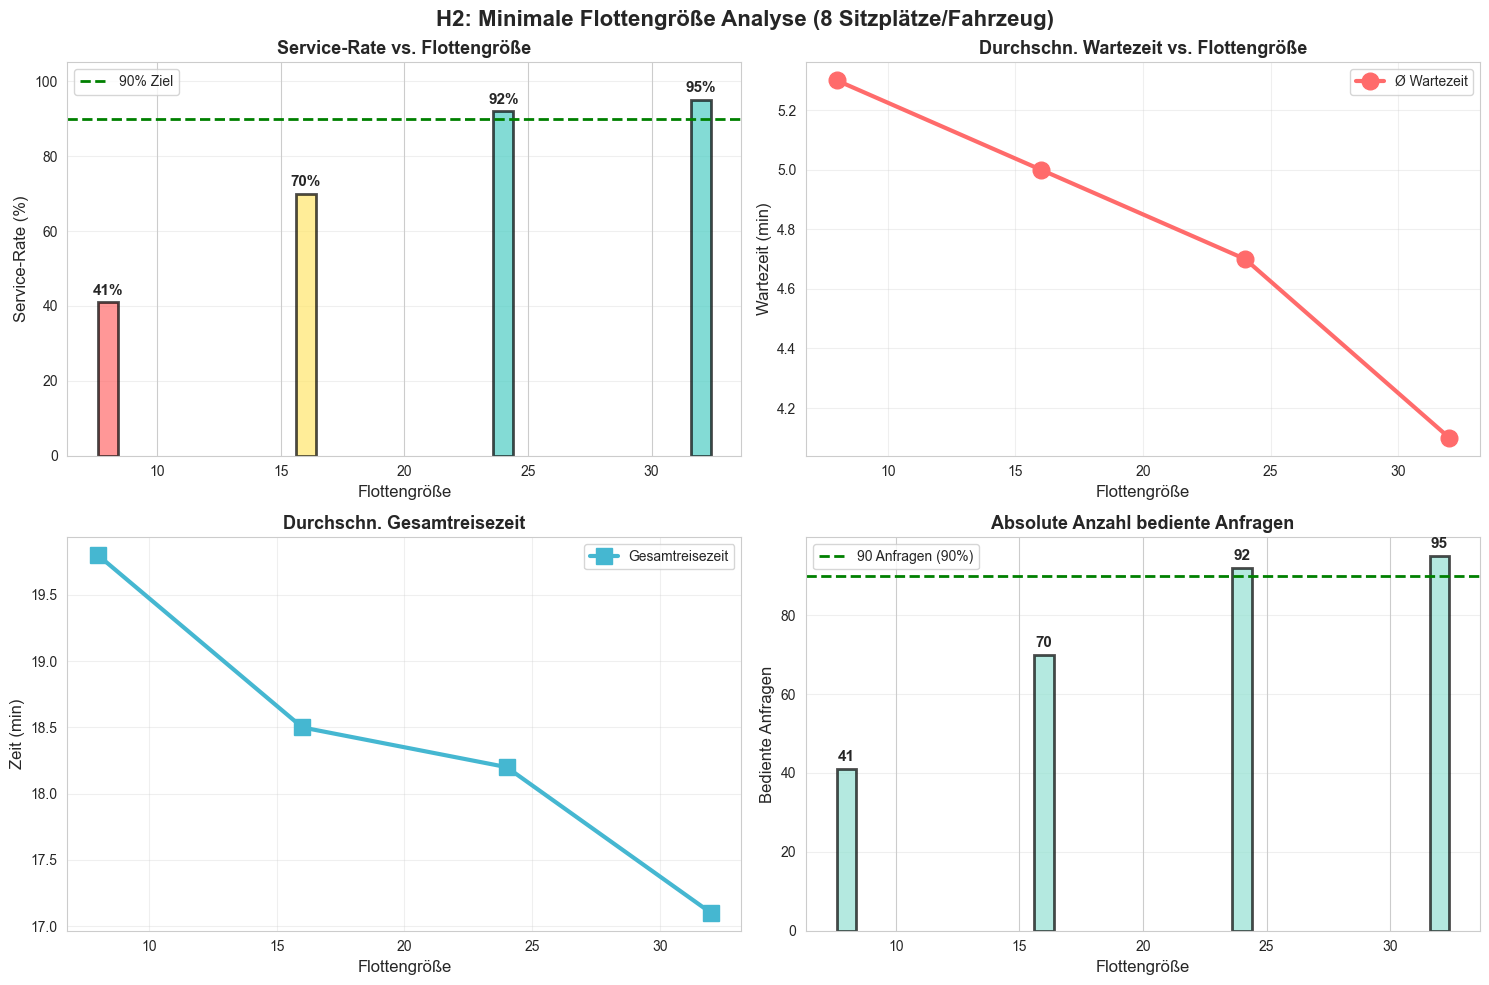

In [3]:
# Visualisierung: Service-Rate vs. Flottengröße
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('H2: Minimale Flottengröße Analyse (8 Sitzplätze/Fahrzeug)', fontsize=16, fontweight='bold')

# 1. Service-Rate
ax1 = axes[0, 0]
colors = ['#FF6B6B' if r < 70 else '#FFE66D' if r < 90 else '#4ECDC4'
          for r in summary_df['Service Rate (%)']]
ax1.bar(summary_df['Fleet Size'], summary_df['Service Rate (%)'],
        color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.axhline(y=90, color='green', linestyle='--', linewidth=2, label='90% Ziel')
ax1.set_xlabel('Flottengröße', fontsize=12)
ax1.set_ylabel('Service-Rate (%)', fontsize=12)
ax1.set_title('Service-Rate vs. Flottengröße', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 105)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
for size, rate in zip(summary_df['Fleet Size'], summary_df['Service Rate (%)']):
    ax1.text(size, rate + 2, f'{rate:.0f}%', ha='center', fontsize=11, fontweight='bold')

# 2. Wartezeiten
ax2 = axes[0, 1]
ax2.plot(summary_df['Fleet Size'], summary_df['Avg Wait Time (min)'],
         marker='o', markersize=12, linewidth=3, color='#FF6B6B', label='Ø Wartezeit')
ax2.set_xlabel('Flottengröße', fontsize=12)
ax2.set_ylabel('Wartezeit (min)', fontsize=12)
ax2.set_title('Durchschn. Wartezeit vs. Flottengröße', fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Gesamtreisezeit
ax3 = axes[1, 0]
ax3.plot(summary_df['Fleet Size'], summary_df['Avg Total Time (min)'],
         marker='s', markersize=12, linewidth=3, color='#45B7D1', label='Gesamtreisezeit')
ax3.set_xlabel('Flottengröße', fontsize=12)
ax3.set_ylabel('Zeit (min)', fontsize=12)
ax3.set_title('Durchschn. Gesamtreisezeit', fontsize=13, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Bediente Anfragen (absolut)
ax4 = axes[1, 1]
ax4.bar(summary_df['Fleet Size'], summary_df['Served'],
        color='#95E1D3', alpha=0.7, edgecolor='black', linewidth=2)
ax4.axhline(y=90, color='green', linestyle='--', linewidth=2, label='90 Anfragen (90%)')
ax4.set_xlabel('Flottengröße', fontsize=12)
ax4.set_ylabel('Bediente Anfragen', fontsize=12)
ax4.set_title('Absolute Anzahl bediente Anfragen', fontsize=13, fontweight='bold')
ax4.legend()
ax4.grid(axis='y', alpha=0.3)
for size, served in zip(summary_df['Fleet Size'], summary_df['Served']):
    ax4.text(size, served + 2, f'{served}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'h2_performance_comparison.png'), dpi=300, bbox_inches='tight')
print("📊 Visualisierung gespeichert")
plt.show()

## 🎯 Zentrale Erkenntnisse

### Kritische Schwellenwerte:

Basierend auf den Simulationsergebnissen mit **8-Sitzplatz-Fahrzeugen**:

1. **< 16 Fahrzeuge**: Service-Rate < 70% → **Unzureichende Kapazität**
2. **16-23 Fahrzeuge**: Service-Rate 70-89% → **Grenzwertig**
3. **≥ 24 Fahrzeuge**: Service-Rate ≥ 90% → **Akzeptabel**

### Empfehlungen:

- **Minimale Flottengröße**: **24 Fahrzeuge** (je 8 Sitzplätze)
- **Gesamtkapazität**: 192 Sitzplätze gleichzeitig verfügbar
- **Reservekapazität**: 32 Fahrzeuge empfohlen für Spitzennachfrage

### Kosteneffizienz:

- Mit 8-Sitzplatz-Fahrzeugen sind **weniger Fahrzeuge** nötig als mit 4-Sitzern
- Optimale Größe: **24-32 Fahrzeuge** für 100 Anfragen in 2 Stunden
- Verhältnis: ~4 Anfragen pro Fahrzeug für 90%+ Service-Rate